# Digital Image Processing Lab — Lab Task 03
## Image Enhancement and Intensity Transformations

**Student Name:** Afzaal Ahmed

**Roll Number:** 2024-SE-40

**Course:** Digital Image Processing Lab 

**Assigned:** 02 November 2026  

**Due:** 09 November 2026

### Objective
Implement and compare grayscale intensity transformations, histogram enhancement, and thresholding. The notebook uses safe arithmetic, clips values to the valid 8-bit range (0–255), and keeps the original image unchanged.

## 0. Import libraries and load the input image

Shape: (1254, 1254)
Data type: uint8
Minimum intensity: 0
Maximum intensity: 255


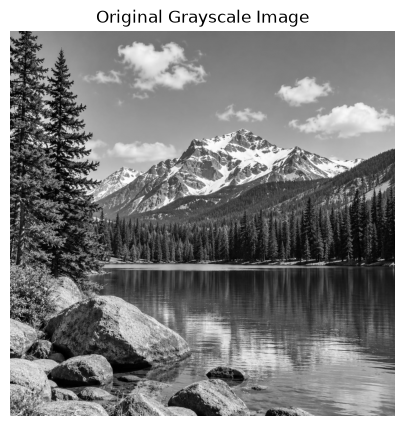

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "Input_img.jpeg"

# Load an 8-bit grayscale image.
img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        f"Could not load '{IMAGE_PATH}'. Put your image beside this notebook "
        "and update IMAGE_PATH."
    )

if img.dtype != np.uint8:
    raise TypeError("The input image must be an 8-bit uint8 grayscale image.")

if img.ndim != 2:
    raise ValueError("The input image must be grayscale (2D).")

if img.shape[0] < 300 or img.shape[1] < 300:
    raise ValueError("Choose an image at least 300 x 300 pixels.")

# Keep the original unchanged; all transformations use separate arrays.
original = img.copy()

print("Shape:", original.shape)
print("Data type:", original.dtype)
print("Minimum intensity:", original.min())
print("Maximum intensity:", original.max())

plt.figure(figsize=(5, 5))
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()


## 1. Brightness adjustment

Formula: `s = r + β`. Positive β makes the image brighter; negative β makes it darker.  
The calculation is performed in `int16` to prevent uint8 overflow, then clipped to 0–255.


### Dry run 1

Input pixels: `[30, 80, 128, 180, 240]`

- For β = +40, raw values are `[70, 120, 168, 220, 280]`; after clipping: `[70, 120, 168, 220, 255]`.
- For β = −40, raw values are `[-10, 40, 88, 140, 200]`; after clipping: `[0, 40, 88, 140, 200]`.

Values outside 0–255 are clipped. This can lose detail in very dark or very bright regions.


Original:        [30, 80, 128, 180, 240]
Raw +40:         [70, 120, 168, 220, 280]
Clipped +40:     [70, 120, 168, 220, 255]
Raw -40:         [-10, 40, 88, 140, 200]
Clipped -40:     [0, 40, 88, 140, 200]
Nested-loop result matches NumPy: True


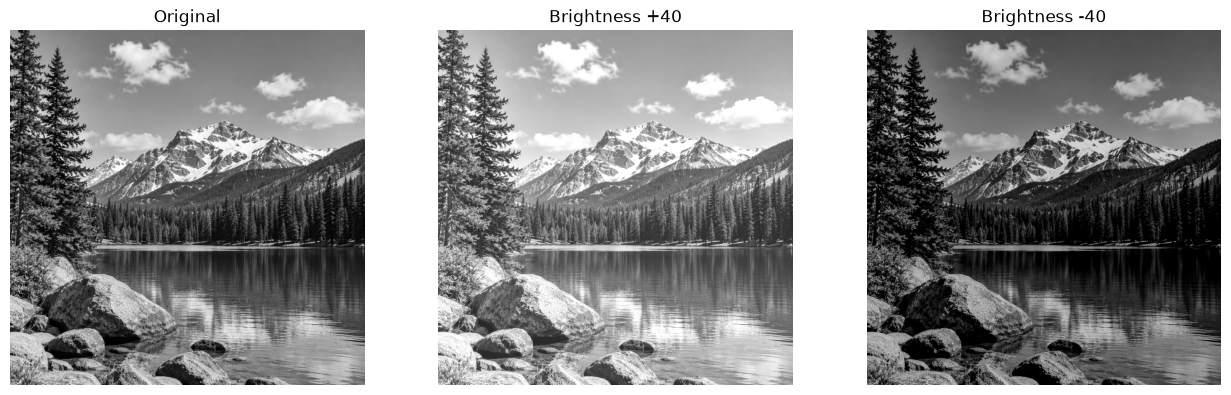

In [26]:
pixels = np.array([30, 80, 128, 180, 240], dtype=np.int16)

raw_plus = pixels + 40
result_plus = np.clip(raw_plus, 0, 255).astype(np.uint8)

raw_minus = pixels - 40
result_minus = np.clip(raw_minus, 0, 255).astype(np.uint8)

print("Original:       ", pixels.tolist())
print("Raw +40:        ", raw_plus.tolist())
print("Clipped +40:    ", result_plus.tolist())
print("Raw -40:        ", raw_minus.tolist())
print("Clipped -40:    ", result_minus.tolist())

# Image operations
img_i16 = original.astype(np.int16)
bright = np.clip(img_i16 + 40, 0, 255).astype(np.uint8)
dark = np.clip(img_i16 - 40, 0, 255).astype(np.uint8)

# Required nested-loop implementation of +40
loop_bright = np.zeros(original.shape, dtype=np.uint8)
for row in range(original.shape[0]):
    for col in range(original.shape[1]):
        value = int(original[row, col]) + 40
        if value > 255:
            value = 255
        loop_bright[row, col] = value

print("Nested-loop result matches NumPy:", np.array_equal(bright, loop_bright))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, image, title in zip(
    axes, [original, bright, dark],
    ["Original", "Brightness +40", "Brightness -40"]
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


**Observation:** Brightness +40 makes the image brighter, while −40 makes it darker. Values above 255 or below 0 are clipped, which may remove highlight or shadow detail.


## 2. Linear contrast from zero

Formula: `s = αr + β`, with α = 1.5 and β = 0. Values are clipped to 0–255 and fractional results are truncated.


### Dry run 2

Input: `[30, 80, 128, 180, 240]`  
Raw `1.5r`: `[45, 120, 192, 270, 360]`  
After clipping and truncation: `[45, 120, 192, 255, 255]`. The last two pixels saturate at 255.


Raw 1.5r: [45.0, 120.0, 192.0, 270.0, 360.0]
Final values: [45, 120, 192, 255, 255]


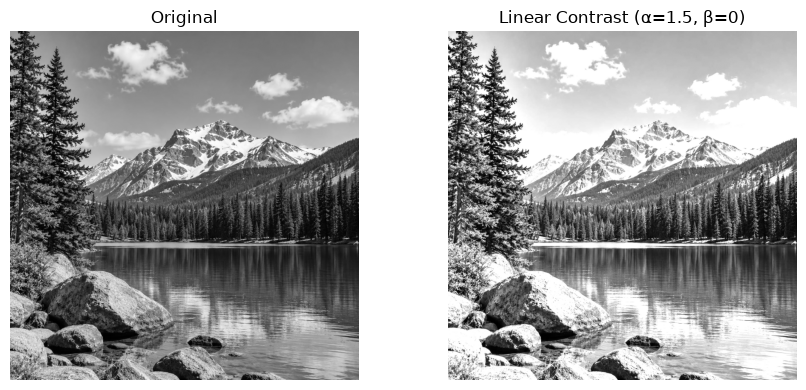

In [27]:
pixels = np.array([30, 80, 128, 180, 240], dtype=np.float32)
raw = 1.5 * pixels
dry_result = np.clip(raw, 0, 255).astype(np.uint8)
print("Raw 1.5r:", raw.tolist())
print("Final values:", dry_result.tolist())

contrast_zero = np.clip(
    original.astype(np.float32) * 1.5, 0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[1].imshow(contrast_zero, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Linear Contrast (α=1.5, β=0)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


**Observation:** Multiplying by 1.5 increases intensity values. Bright pixels can saturate at 255, causing highlight detail to be lost.


## 3. Contrast centered at 128

Formula: `s = (r − 128)α + 128`. α = 1.5 increases contrast; α = 0.5 decreases contrast. The midpoint 128 stays unchanged.


### Dry run 3

Input: `[30, 80, 128, 180, 240]`

- α = 1.5: intermediate `r−128` = `[-98, -48, 0, 52, 112]`; raw output = `[-19, 56, 128, 206, 296]`; clipped output = `[0, 56, 128, 206, 255]`.
- α = 0.5: raw and final output = `[79, 104, 128, 154, 184]`.


r - 128: [-98.0, -48.0, 0.0, 52.0, 112.0]
Raw α=1.5: [-19.0, 56.0, 128.0, 206.0, 296.0]
Final α=1.5: [0, 56, 128, 206, 255]
Raw α=0.5: [79.0, 104.0, 128.0, 154.0, 184.0]
Final α=0.5: [79, 104, 128, 154, 184]


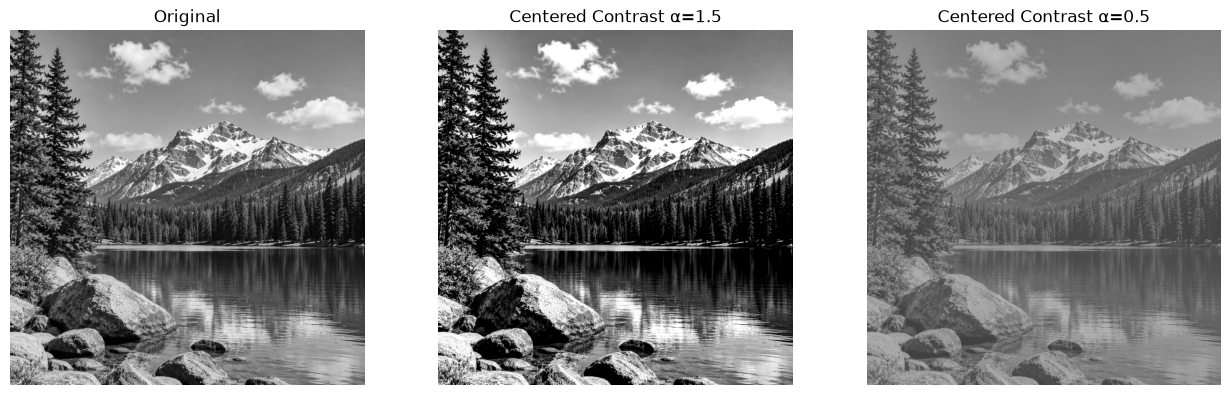

In [28]:
pixels = np.array([30, 80, 128, 180, 240], dtype=np.float32)
centered = pixels - 128
raw_15 = centered * 1.5 + 128
raw_05 = centered * 0.5 + 128
print("r - 128:", centered.tolist())
print("Raw α=1.5:", raw_15.tolist())
print("Final α=1.5:", np.clip(raw_15, 0, 255).astype(np.uint8).tolist())
print("Raw α=0.5:", raw_05.tolist())
print("Final α=0.5:", np.clip(raw_05, 0, 255).astype(np.uint8).tolist())

source = original.astype(np.float32)
contrast_high = np.clip((source - 128) * 1.5 + 128, 0, 255).astype(np.uint8)
contrast_low = np.clip((source - 128) * 0.5 + 128, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, image, title in zip(
    axes, [original, contrast_high, contrast_low],
    ["Original", "Centered Contrast α=1.5", "Centered Contrast α=0.5"]
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


**Observation:** α = 1.5 spreads values farther from 128 and increases contrast; α = 0.5 moves values toward 128 and reduces contrast. A pixel equal to 128 remains 128.


## 4. Image negative

Formula: `s = 255 − r`. A negative can make features easier to inspect when dark structures are more visible against a bright background, for example in some medical images.


### Dry run 4

Input `[30, 80, 128, 180, 240]` becomes `[225, 175, 127, 75, 15]`. Applying the negative again gives the original values because `255 − (255 − r) = r`.


Negative: [225, 175, 127, 75, 15]
Negative again: [30, 80, 128, 180, 240]
Original restored exactly: True


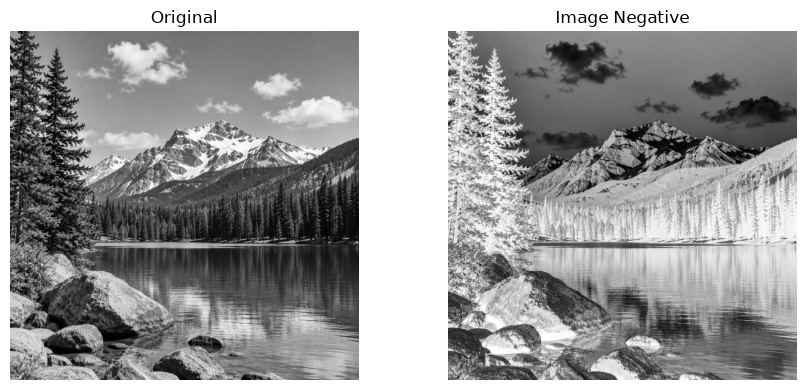

In [29]:
pixels = np.array([30, 80, 128, 180, 240], dtype=np.uint8)
dry_negative = 255 - pixels
print("Negative:", dry_negative.tolist())
print("Negative again:", (255 - dry_negative).tolist())

negative = 255 - original
negative_again = 255 - negative
print("Original restored exactly:", np.array_equal(original, negative_again))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[1].imshow(negative, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Image Negative")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


**Observation:** The negative swaps dark and bright intensities. Applying the negative transformation twice restores the original image.


## 5. Gamma correction

Formula: `s = 255(r/255)^γ`. In this lab's convention, γ = 0.5 brightens darker regions and γ = 2.0 darkens them. Zero and 255 remain fixed.


### Dry run 5

Input: `[0, 64, 128, 192, 255]`. Normalize each pixel by 255, raise it to γ, then multiply by 255. Keep full precision until the final output; truncate (do not round).

- γ = 0.5: `[0, 127, 180, 221, 255]`
- γ = 2.0: `[0, 16, 64, 144, 255]`

For example, at r=64 and γ=0.5: `255 × (64/255)^0.5 ≈ 127.75`, truncated to 127.


Normalized: [0.         0.25098039 0.50196078 0.75294118 1.        ]
Power γ=0.5: [0.         0.50097943 0.70849191 0.86772183 1.        ]
Scaled γ=0.5: [  0.         127.74975538 180.66543665 221.26906698 255.        ]
Final γ=0.5: [0, 127, 180, 221, 255]
Power γ=2.0: [0.         0.06299116 0.25196463 0.56692042 1.        ]
Scaled γ=2.0: [  0.          16.0627451   64.25098039 144.56470588 255.        ]
Final γ=2.0: [0, 16, 64, 144, 255]
γ=0.5 keeps endpoints: 0 255
γ=2.0 keeps endpoints: 0 255


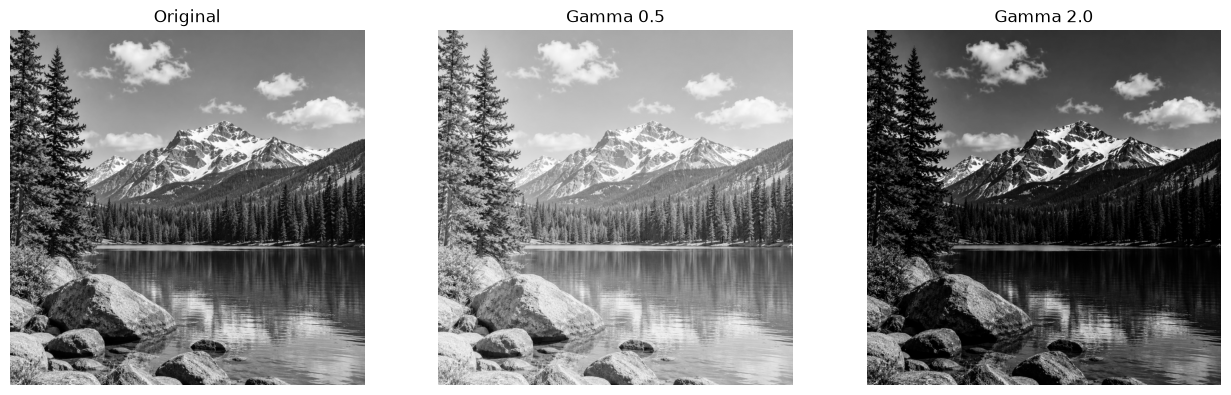

In [30]:
pixels = np.array([0, 64, 128, 192, 255], dtype=np.float64)
normalized = pixels / 255.0
power_05 = normalized ** 0.5
power_20 = normalized ** 2.0
scaled_05 = 255 * power_05
scaled_20 = 255 * power_20

print("Normalized:", normalized)
print("Power γ=0.5:", power_05)
print("Scaled γ=0.5:", scaled_05)
print("Final γ=0.5:", scaled_05.astype(np.uint8).tolist())
print("Power γ=2.0:", power_20)
print("Scaled γ=2.0:", scaled_20)
print("Final γ=2.0:", scaled_20.astype(np.uint8).tolist())

source = original.astype(np.float64) / 255.0
gamma_05 = (255 * (source ** 0.5)).astype(np.uint8)
gamma_20 = (255 * (source ** 2.0)).astype(np.uint8)
print("γ=0.5 keeps endpoints:", gamma_05.min(), gamma_05.max())
print("γ=2.0 keeps endpoints:", gamma_20.min(), gamma_20.max())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, image, title in zip(
    axes, [original, gamma_05, gamma_20],
    ["Original", "Gamma 0.5", "Gamma 2.0"]
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


**Observation:** γ = 0.5 brightens dark regions, while γ = 2.0 darkens them. The endpoints 0 and 255 remain unchanged. Fractional values are truncated at the final conversion to uint8.


## 6. Grayscale histogram

A 256-bin histogram counts how many pixels have each intensity. The histogram shows intensity frequencies, not the spatial positions of pixels.


### Dry run 6

Given matrix `[[0, 50, 50, 100], [100, 150, 200, 255]]`, there are 8 pixels.

Nonzero frequencies: 0:1, 50:2, 100:2, 150:1, 200:1, 255:1.  
Probabilities: 0.125, 0.25, 0.25, 0.125, 0.125, 0.125 respectively. Total frequency = 8 and total probability = 1.


Total pixel count: 8
Intensity : Frequency : Probability
        0 :         1 : 0.125
       50 :         2 : 0.250
      100 :         2 : 0.250
      150 :         1 : 0.125
      200 :         1 : 0.125
      255 :         1 : 0.125


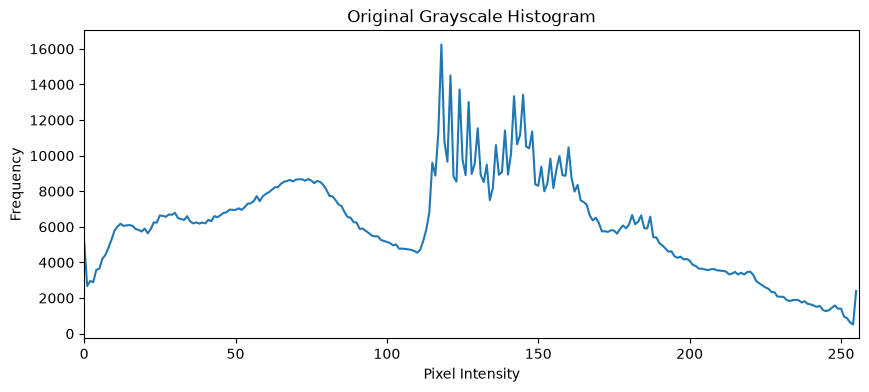

In [31]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]], dtype=np.uint8)
values, counts = np.unique(A, return_counts=True)
print("Total pixel count:", A.size)
print("Intensity : Frequency : Probability")
for value, count in zip(values, counts):
    print(f"{value:9d} : {count:9d} : {count / A.size:.3f}")

hist = cv2.calcHist([original], [0], None, [256], [0, 256])
plt.figure(figsize=(10, 4))
plt.plot(hist)
plt.title("Original Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 256)
plt.show()


**Interpretation (write after viewing your graph):** The histogram shows which intensity ranges occur most often in this image. A concentration toward low intensities indicates a darker image, while a concentration toward high intensities indicates a brighter image; the histogram does not reveal where those pixels occur.


## 7. Global histogram equalization

OpenCV's `cv2.equalizeHist` applies global histogram equalization to an 8-bit grayscale image. It can improve global contrast but may also make noise more visible.


### Dry run 7

Input pixels: `[50, 50, 100, 150]`. Frequencies are 2, 1, 1; cumulative counts are 2, 3, 4; CDF values are 0.50, 0.75, 1.00.

- Mapping `255 × CDF`, rounded half-up: `[128, 128, 191, 255]`.
- With `CDFmin = 0.50`, mapping `255 × (CDF − CDFmin)/(1 − CDFmin)`, rounded half-up: `[0, 0, 128, 255]`.

The normalized second mapping is the min-CDF formula requested in the lab. OpenCV uses its own discrete lookup-table implementation, so compare the OpenCV result rather than assuming every hand calculation will match exactly.


Intensity: [50, 100, 150]
Frequencies: [2, 1, 1]
Cumulative counts: [2, 3, 4]
CDF: [0.5, 0.75, 1.0]
Mapping 255*CDF: [128, 191, 255]
Mapping using CDFmin: [0, 128, 255]
Output list 1: [128, 128, 191, 255]
Output list 2: [0, 0, 128, 255]


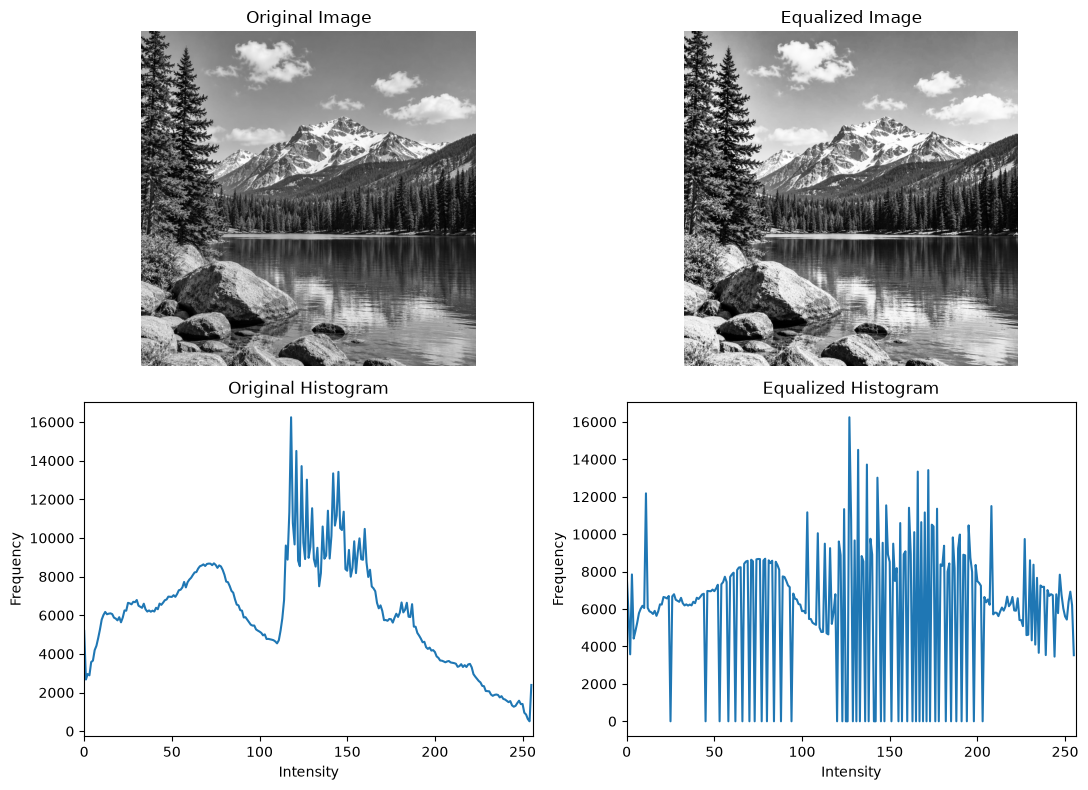

In [32]:
# Dry run frequencies and CDF
dry = np.array([50, 50, 100, 150], dtype=np.uint8)
unique, counts = np.unique(dry, return_counts=True)
cdf = np.cumsum(counts) / dry.size
cdf_min = cdf[0]

# Round half up for nonnegative values: floor(x + 0.5)
map1 = np.floor(255 * cdf + 0.5).astype(int)
map2 = np.floor(255 * (cdf - cdf_min) / (1 - cdf_min) + 0.5).astype(int)

print("Intensity:", unique.tolist())
print("Frequencies:", counts.tolist())
print("Cumulative counts:", np.cumsum(counts).tolist())
print("CDF:", cdf.tolist())
print("Mapping 255*CDF:", map1.tolist())
print("Mapping using CDFmin:", map2.tolist())

# Show both mapped lists for every original pixel
lookup1 = dict(zip(unique.tolist(), map1.tolist()))
lookup2 = dict(zip(unique.tolist(), map2.tolist()))
print("Output list 1:", [lookup1[int(x)] for x in dry])
print("Output list 2:", [lookup2[int(x)] for x in dry])

equalized = cv2.equalizeHist(original)
hist_original = cv2.calcHist([original], [0], None, [256], [0, 256])
hist_equalized = cv2.calcHist([equalized], [0], None, [256], [0, 256])

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Image")
axes[0, 1].imshow(equalized, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Equalized Image")
axes[1, 0].plot(hist_original)
axes[1, 0].set_title("Original Histogram")
axes[1, 1].plot(hist_equalized)
axes[1, 1].set_title("Equalized Histogram")
for ax in axes[0]:
    ax.axis("off")
for ax in axes[1]:
    ax.set_xlim(0, 256)
    ax.set_xlabel("Intensity")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()


**Observation:** Global equalization redistributes the image's intensity range and may reveal details when the original contrast is low. It can also amplify noise, so inspect the output rather than assuming it always improves the image.


## 8. CLAHE (Contrast Limited Adaptive Histogram Equalization)

CLAHE divides the image into tiles and performs local equalization. The tile grid `(8, 8)` means 8 tile rows and 8 tile columns, not tiles that are 8 × 8 pixels. Neighboring tile mappings are interpolated to reduce visible boundaries.


### Dry run 8

Four-bin histogram: `[6, 2, 0, 0]`, with an absolute cap of 4.

1. Clip counts: `[4, 2, 0, 0]`; excess = 2.
2. Redistribute excess equally: 2/4 = 0.5 per bin.
3. New histogram: `[4.5, 2.5, 0.5, 0.5]`, total = 8.
4. New CDF: `[0.5625, 0.875, 0.9375, 1.0]`.

This simplified absolute cap is only a dry-run exercise; it is not the same as OpenCV's `clipLimit=2.0` parameter or its integer redistribution details.


Clipped histogram: [4.0, 2.0, 0.0, 0.0]
Excess: 2
Redistributed histogram: [4.5, 2.5, 0.5, 0.5]
Total: 8.0
New CDF: [0.5625, 0.875, 0.9375, 1.0]


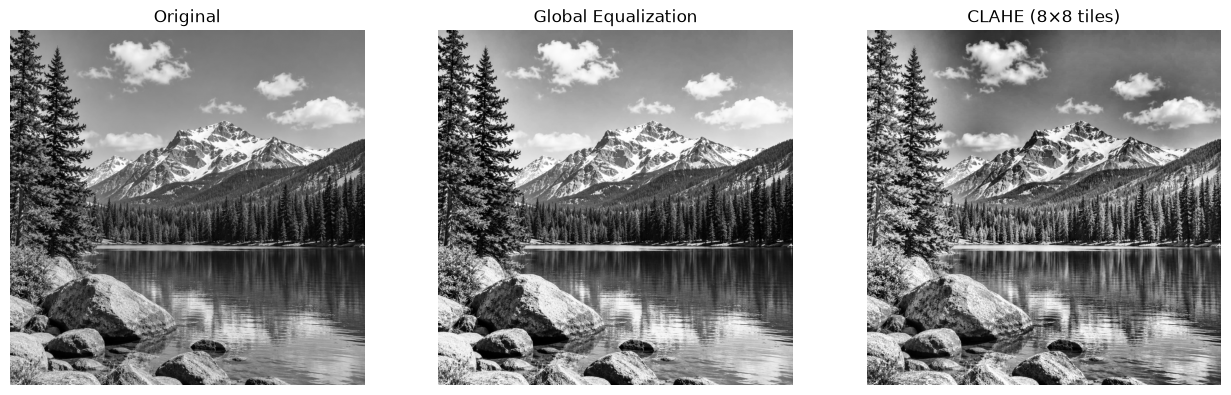

In [33]:
clipped_hist = np.array([4.0, 2.0, 0.0, 0.0])
excess = 6 - 4
redistributed_hist = clipped_hist + excess / 4
new_cdf = np.cumsum(redistributed_hist) / redistributed_hist.sum()

print("Clipped histogram:", clipped_hist.tolist())
print("Excess:", excess)
print("Redistributed histogram:", redistributed_hist.tolist())
print("Total:", redistributed_hist.sum())
print("New CDF:", new_cdf.tolist())

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_image = clahe.apply(original)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, image, title in zip(
    axes, [original, equalized, clahe_image],
    ["Original", "Global Equalization", "CLAHE (8×8 tiles)"]
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


**Observation:** CLAHE enhances contrast locally and is often useful when lighting is uneven across an image. The clip limit restricts excessive local contrast enhancement, helping control noise amplification.


## 9. Fixed binary thresholding

For `THRESH_BINARY`, OpenCV outputs 255 when a pixel is greater than the threshold and 0 otherwise. A pixel equal to the threshold becomes 0.


### Dry run 9

Input: `[0, 80, 127, 128, 180, 255]`.

- T = 127 → `[0, 0, 0, 255, 255, 255]`; white-pixel count = 3.
- T = 180 → `[0, 0, 0, 0, 0, 255]`; white-pixel count = 1.


In [ ]:
pixels = np.array([0, 80, 127, 128, 180, 255], dtype=np.uint8)
for T in [127, 180]:
    result = np.where(pixels > T, 255, 0).astype(np.uint8)
    print(f"T={T}: {result.tolist()}, white pixels={np.count_nonzero(result == 255)}")

threshold_value, binary = cv2.threshold(
    original, 127, 255, cv2.THRESH_BINARY
)
print("Threshold used:", threshold_value)
print("Unique output values:", np.unique(binary))

plt.figure(figsize=(6, 5))
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Binary Threshold (T=127)")
plt.axis("off")
plt.show()


**Observation:** Fixed thresholding separates pixels into black and white using one threshold for the entire image. It is simple but may perform poorly when lighting varies across the image.


## 10. Otsu thresholding

Otsu chooses a global threshold by maximizing between-class variance: `w0 × w1 × (μ0 − μ1)²`. Classes are split as `r ≤ T` and `r > T`. When multiple thresholds tie, the dry-run instruction says to choose the smallest T.


### Dry run 10

Input: `[0, 1, 4, 5]`. For T = 0, 1, 2, 3, 4, the between-class variances are approximately:

- T=0: 2.0833
- T=1: 4.0000
- T=2: 4.0000
- T=3: 4.0000
- T=4: 2.0833

The maximum is tied at T=1, 2, and 3, so choose the smallest: **T=1**. Predicted mask: `[0, 0, 255, 255]`.


T=0: w0=0.25, w1=0.75, mu0=0.0000, mu1=3.3333, variance=2.0833
T=1: w0=0.50, w1=0.50, mu0=0.5000, mu1=4.5000, variance=4.0000
T=2: w0=0.50, w1=0.50, mu0=0.5000, mu1=4.5000, variance=4.0000
T=3: w0=0.50, w1=0.50, mu0=0.5000, mu1=4.5000, variance=4.0000
T=4: w0=0.75, w1=0.25, mu0=1.6667, mu1=5.0000, variance=2.0833
Smallest threshold among maximum-score ties: 1
Predicted mask: [0, 0, 255, 255]
OpenCV Otsu threshold: 1.0
OpenCV mask: [[0, 0, 255, 255]]
Image Otsu threshold: 107.0


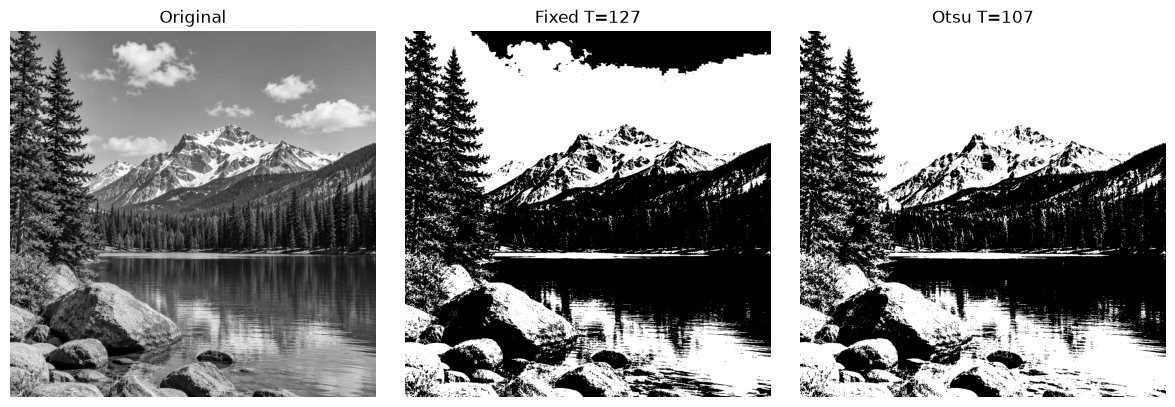

In [ ]:
dry = np.array([0, 1, 4, 5], dtype=np.float64)
scores = []

for T in [0, 1, 2, 3, 4]:
    class0 = dry[dry <= T]
    class1 = dry[dry > T]
    if len(class0) == 0 or len(class1) == 0:
        score = 0.0
        w0 = len(class0) / len(dry)
        w1 = len(class1) / len(dry)
        mu0 = np.nan if len(class0) == 0 else class0.mean()
        mu1 = np.nan if len(class1) == 0 else class1.mean()
    else:
        w0 = len(class0) / len(dry)
        w1 = len(class1) / len(dry)
        mu0 = class0.mean()
        mu1 = class1.mean()
        score = w0 * w1 * (mu0 - mu1) ** 2
    scores.append(score)
    print(
        f"T={T}: w0={w0:.2f}, w1={w1:.2f}, "
        f"mu0={mu0:.4f}, mu1={mu1:.4f}, variance={score:.4f}"
    )

best_score = max(scores)
best_T = min(T for T, score in zip([0, 1, 2, 3, 4], scores)
             if np.isclose(score, best_score))
print("Smallest threshold among maximum-score ties:", best_T)
print("Predicted mask:", np.where(dry > best_T, 255, 0).astype(np.uint8).tolist())

# Verify using OpenCV on the same small image
dry_uint8 = np.array([[0, 1, 4, 5]], dtype=np.uint8)
cv_t, cv_mask = cv2.threshold(
    dry_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
print("OpenCV Otsu threshold:", cv_t)
print("OpenCV mask:", cv_mask.tolist())

# Apply Otsu to the actual image
otsu_value, otsu_image = cv2.threshold(
    original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
print("Image Otsu threshold:", otsu_value)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[1].imshow(binary, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Fixed T=127")
axes[2].imshow(otsu_image, cmap="gray", vmin=0, vmax=255)
axes[2].set_title(f"Otsu T={otsu_value:.0f}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


**Observation:** Otsu automatically selects a threshold based on the image histogram. Compare its mask with the fixed-threshold mask; Otsu is most suitable when foreground and background form reasonably distinct intensity groups.


## 11. Adaptive Gaussian thresholding

Adaptive thresholding calculates a local threshold for each pixel from its neighborhood. The required image settings are `blockSize=11` and `C=2`. The block size must be an odd number greater than 1.


### Dry run 11

Neighborhood:
`[[100,100,100], [100,120,140], [140,140,140]]`

Gaussian weights:
`[[1,2,1], [2,4,2], [1,2,1]] / 16`

Weighted sum = 1920, so weighted mean = 1920/16 = 120.  
Threshold T = mean − C = 120 − 2 = 118.

Center pixel 120 is greater than 118, so output = 255. A pixel equal to 118 is not greater than T, so output = 0.


Weighted mean: 120.0
Local threshold: 118.0
Center pixel: 120.0
Center output: 255
Pixel equal to threshold output: 0


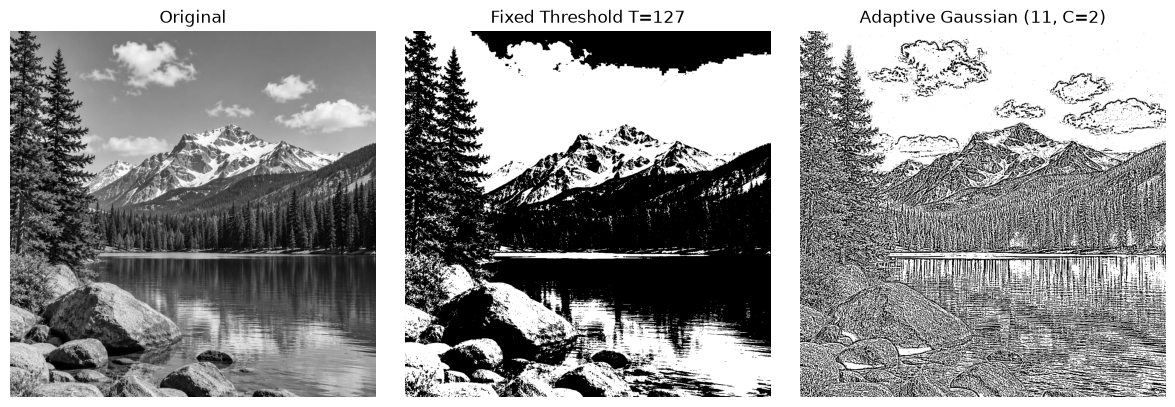

In [ ]:
neighborhood = np.array([
    [100, 100, 100],
    [100, 120, 140],
    [140, 140, 140]
], dtype=np.float64)

weights = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float64) / 16

weighted_mean = np.sum(neighborhood * weights)
T = weighted_mean - 2
center_pixel = neighborhood[1, 1]

print("Weighted mean:", weighted_mean)
print("Local threshold:", T)
print("Center pixel:", center_pixel)
print("Center output:", 255 if center_pixel > T else 0)
print("Pixel equal to threshold output:", 255 if T > T else 0)

adaptive = cv2.adaptiveThreshold(
    original,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, image, title in zip(
    axes, [original, binary, adaptive],
    ["Original", "Fixed Threshold T=127", "Adaptive Gaussian (11, C=2)"]
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


**Observation:** Adaptive Gaussian thresholding uses a Gaussian-weighted local neighborhood to calculate a threshold. It can work better than one global threshold when the image has uneven illumination.


## 12. Key concepts required in the report

### Clipping
Clipping restricts pixel values to the valid 8-bit range 0–255. For example, 280 becomes 255 and −10 becomes 0.

### Overflow and safe arithmetic
An image stored as `uint8` cannot represent values outside 0–255. Arithmetic directly in this type can wrap around. Convert to a wider type such as `int16` or `float32`, perform the operation, clip to 0–255, and then convert back to `uint8`.

### Brightness versus contrast
Brightness shifts intensity values up or down. Contrast changes the separation between darker and brighter intensity values.

### Gamma convention
This lab uses `s = 255(r/255)^γ`. Under this convention, γ < 1 brightens mid/dark tones and γ > 1 darkens them.

### Global versus local enhancement
Global equalization uses one mapping for the whole image. CLAHE uses local tiles and can be useful under uneven lighting.

### Global versus local thresholding
Fixed and Otsu thresholding use one global threshold. Adaptive thresholding uses local neighborhoods and can be more useful when illumination changes across the image.

### Resolution versus bit depth
Resolution describes the number of pixels in an image. Bit depth describes how many intensity levels each pixel can represent.
